In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    log_loss
)

In [2]:
data = {
    'Practice_Tests_Completed': [0,1,2,3,4,5,1,2,3,4],
    'Placement_Eligible': [0,0,0,1,1,1,0,0,1,1]
}

df = pd.DataFrame(data)

print(df)

   Practice_Tests_Completed  Placement_Eligible
0                         0                   0
1                         1                   0
2                         2                   0
3                         3                   1
4                         4                   1
5                         5                   1
6                         1                   0
7                         2                   0
8                         3                   1
9                         4                   1


In [3]:
X = df[['Practice_Tests_Completed']]
y = df['Placement_Eligible']

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

print("Training data:", len(X_train))
print("Testing data:", len(X_test))

Training data: 7
Testing data: 3


In [5]:
model = LogisticRegression()

model.fit(X_train, y_train)

print("Intercept:", model.intercept_)
print("Coefficient:", model.coef_)

Intercept: [-3.02424528]
Coefficient: [[1.22460002]]


In [6]:
y_pred = model.predict(X_test)

print("Actual values:")
print(y_test.values)

print("Predicted values:")
print(y_pred)

Actual values:
[0 0 1]
Predicted values:
[0 0 1]


In [7]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Accuracy Percentage:", accuracy * 100)

Accuracy: 1.0
Accuracy Percentage: 100.0


In [8]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[2 0]
 [0 1]]


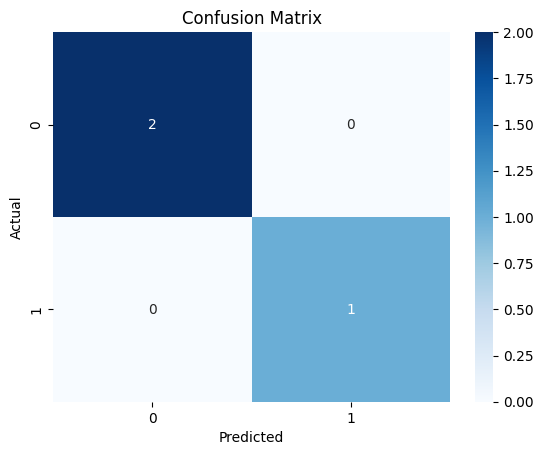

In [9]:
import seaborn as sns

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.show()

In [10]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00         2
           1       1.00      1.00      1.00         1

    accuracy                           1.00         3
   macro avg       1.00      1.00      1.00         3
weighted avg       1.00      1.00      1.00         3



In [11]:
new_students = pd.DataFrame({
    'Practice_Tests_Completed': [0, 1, 2, 3, 4, 5, 6]
})

predictions = model.predict(new_students)

probabilities = model.predict_proba(new_students)

result = new_students.copy()

result['Placement_Prediction'] = predictions
result['Eligibility_Probability'] = probabilities[:, 1]

print(result)

   Practice_Tests_Completed  Placement_Prediction  Eligibility_Probability
0                         0                     0                 0.046342
1                         1                     0                 0.141894
2                         2                     0                 0.360073
3                         3                     1                 0.656910
4                         4                     1                 0.866938
5                         5                     1                 0.956841
6                         6                     1                 0.986918


C:\Users\User\AppData\Roaming\Python\Python312\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


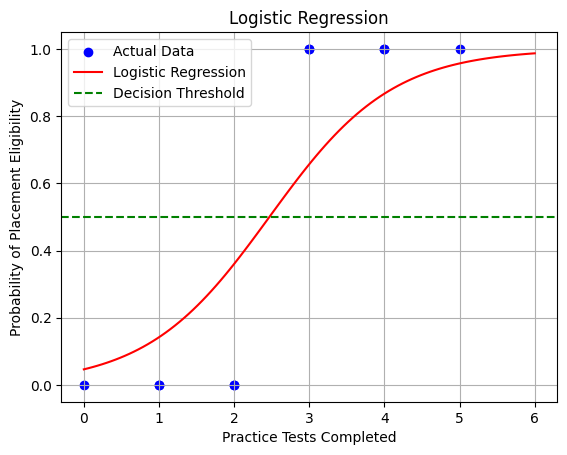

In [12]:
X_range = np.linspace(0, 6, 100).reshape(-1, 1)

probabilities = model.predict_proba(X_range)[:, 1]

plt.scatter(X, y, color='blue', label='Actual Data')

plt.plot(
    X_range,
    probabilities,
    color='red',
    label='Logistic Regression'
)

plt.axhline(y=0.5, color='green', linestyle='--',
            label='Decision Threshold')

plt.xlabel('Practice Tests Completed')
plt.ylabel('Probability of Placement Eligibility')

plt.title('Logistic Regression')
plt.legend()
plt.grid()
plt.show()